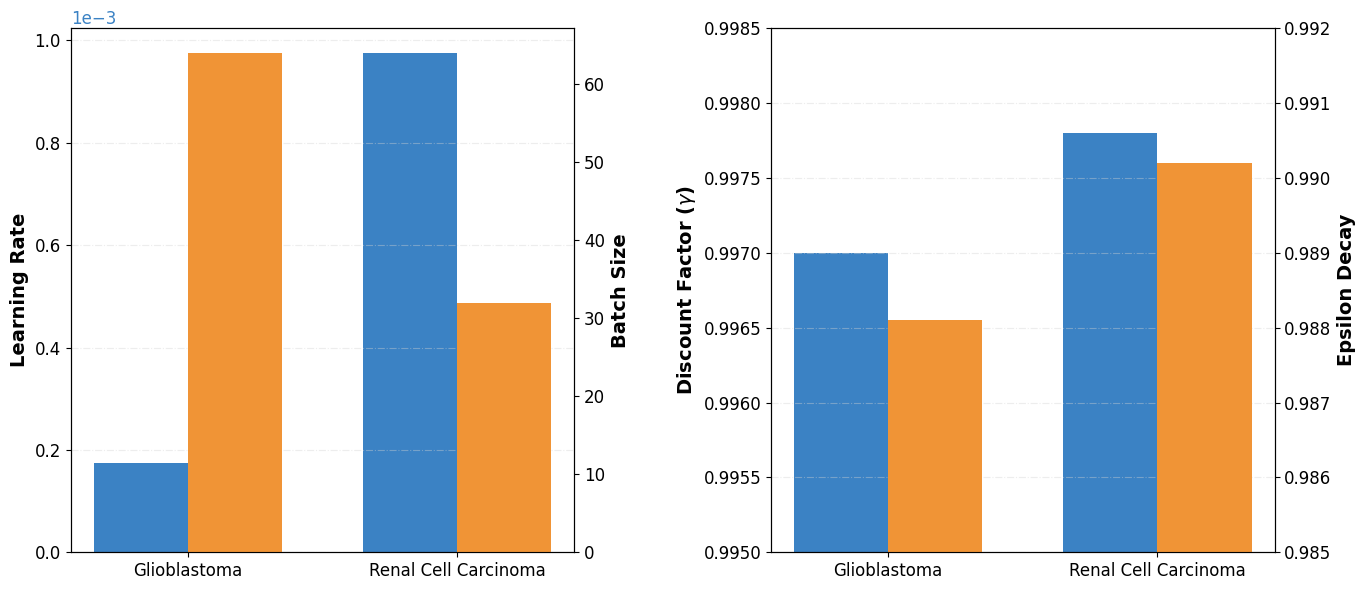

In [1]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Extract data from the LaTeX table
pathologies = ['Glioblastoma', 'Renal Cell Carcinoma']
learning_rate = [1.735e-4, 9.752e-4]
batch_size = [64, 32]
gamma = [0.9970, 0.9978]
epsilon_decay = [0.9881, 0.9902]

# 2. Style configuration (matching the image)
color_blue = '#3b82c4'   # Muted Matplotlib-style blue
color_orange = '#f09436' # Muted Matplotlib-style orange
width = 0.35             # Bar width
x = np.arange(len(pathologies))

# Create the 1x2 subplot figure
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

# ==========================================
# PLOT 1: Learning Rate & Batch Size
# ==========================================
ax1_right = ax1.twinx()

# Plot the dual bars side-by-side
ax1.bar(x - width/2, learning_rate, width, color=color_blue)
ax1_right.bar(x + width/2, batch_size, width, color=color_orange)

# Left Axis (Blue) - Learning Rate
ax1.set_ylabel('Learning Rate', color="black", fontsize=14, fontweight='bold')
ax1.tick_params(axis='y', labelcolor="black", labelsize=12)
ax1.ticklabel_format(style='sci', axis='y', scilimits=(0,0))
ax1.yaxis.get_offset_text().set_color(color_blue)
ax1.yaxis.get_offset_text().set_fontsize(12)

# Right Axis (Orange) - Batch Size
ax1_right.set_ylabel('Batch Size', color="black", fontsize=14, fontweight='bold')
ax1_right.tick_params(axis='y', labelcolor="black", labelsize=12)

# Styling and Grid
ax1.set_xticks(x)
ax1.set_xticklabels(pathologies, fontsize=12)
ax1.grid(axis='y', linestyle='-.', alpha=0.4, color='lightgray')

#add some more space between the two subplots
plt.subplots_adjust(wspace=100)

# ==========================================
# PLOT 2: Discount Factor & Epsilon Decay
# ==========================================
ax2_right = ax2.twinx()

# Because values are very close to 1.0, we offset the bottom to show variance
base_gamma, base_eps = 0.9900, 0.9800

# Plot the dual bars side-by-side (subtracting base to start bars higher up)
ax2.bar(x - width/2, [g - base_gamma for g in gamma], width, bottom=base_gamma, color=color_blue)
ax2_right.bar(x + width/2, [e - base_eps for e in epsilon_decay], width, bottom=base_eps, color=color_orange)

# Left Axis (Blue) - Gamma
ax2.set_ylabel(r'Discount Factor ($\gamma$)', color="black", fontsize=14, fontweight='bold')
ax2.tick_params(axis='y', labelcolor="black", labelsize=12)
ax2.set_ylim(0.9950, 0.9985) # Zoom in to show the variance

# Right Axis (Orange) - Epsilon Decay
ax2_right.set_ylabel('Epsilon Decay', color="black", fontsize=14, fontweight='bold')
ax2_right.tick_params(axis='y', labelcolor="black", labelsize=12)
ax2_right.set_ylim(0.9850, 0.9920) # Zoom in to show the variance

# Styling and Grid
ax2.set_xticks(x)
ax2.set_xticklabels(pathologies, fontsize=12)
ax2.grid(axis='y', linestyle='-.', alpha=0.4, color='lightgray')

# Final layout adjustments
plt.tight_layout()

#save the figure as pdf
plt.savefig('pathology_hyperparameters.pdf', format='pdf', bbox_inches='tight')

plt.show()

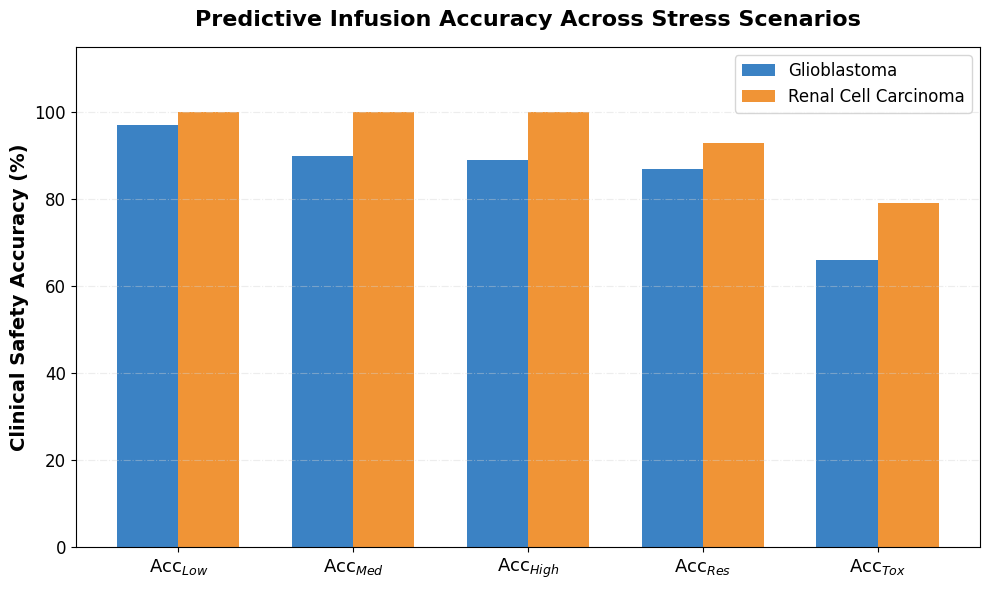

In [4]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Extract data from the LaTeX table
scenarios = ['Acc$_{Low}$', 'Acc$_{Med}$', 'Acc$_{High}$', 'Acc$_{Res}$', 'Acc$_{Tox}$']
glio_acc = [97.0, 90.0, 89.0, 87.0, 66.0]
renal_acc = [100.0, 100.0, 100.0, 93.0, 79.0]

# 2. Style configuration (matching previous plots)
color_blue = '#3b82c4'   # Muted Matplotlib-style blue for Glioblastoma
color_orange = '#f09436' # Muted Matplotlib-style orange for Renal Cell Carcinoma
width = 0.35             # Width of the individual bars

x = np.arange(len(scenarios))  # Label locations

# Create the figure
fig, ax = plt.subplots(figsize=(10, 6))

# ==========================================
# PLOT: Grouped Bars
# ==========================================
bars1 = ax.bar(x - width/2, glio_acc, width, label='Glioblastoma', color=color_blue)
bars2 = ax.bar(x + width/2, renal_acc, width, label='Renal Cell Carcinoma', color=color_orange)

# Styling and Grid
ax.set_title('Predictive Infusion Accuracy Across Stress Scenarios', fontsize=16, fontweight='bold', pad=15)
ax.set_ylabel('Clinical Safety Accuracy (%)', fontsize=14, fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(scenarios, fontsize=13)
ax.set_ylim(0, 115) # Extended slightly to fit the legend and labels
ax.tick_params(axis='y', labelsize=12)
ax.grid(axis='y', linestyle='-.', alpha=0.4, color='lightgray')

# Add legend
ax.legend(fontsize=12, loc='upper right')

# # Add value labels on top of the bars
# def add_labels(bars):
#     for bar in bars:
#         yval = bar.get_height()
#         ax.text(bar.get_x() + bar.get_width()/2, yval + 1.5, f'{yval:.1f}%', 
#                  ha='center', va='bottom', fontsize=10, fontweight='bold')

# add_labels(bars1)
# add_labels(bars2)

# Final layout adjustments
plt.tight_layout()

plt.savefig('pathology_accuracy.pdf', format='pdf', bbox_inches='tight')

plt.show()